In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")






All libraries imported successfully!


In [2]:
# Load Netflix dataset
df = pd.read_csv("../dataset/netflix_titles.csv")

# Display success message
print("Netflix dataset loaded successfully!")

# Display dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display first 5 records
df.head()

Netflix dataset loaded successfully!
Number of Rows: 8807
Number of Columns: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
# 1. Dataset information
print("DATASET INFORMATION")
df.info()

# 2. Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

# 4. Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe(include="all"))

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB

MISSING VALUES
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description   

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [4]:
# Calculate missing values
missing_values = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (missing_values / len(df)) * 100

# Create summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

# Display columns with missing values
missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

print("MISSING VALUE ANALYSIS")
display(missing_summary)

MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
director,2634,29.91
cast,825,9.37
country,831,9.44
date_added,10,0.11
rating,4,0.05
duration,3,0.03


In [5]:
# Create a copy of the original dataset
df_clean = df.copy()

# Replace missing categorical values
columns_to_fill = ["director", "cast", "country", "rating"]

for column in columns_to_fill:
    df_clean[column] = df_clean[column].fillna("Unknown")

# Check missing values after cleaning
print("DATA CLEANING COMPLETED")

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDataset shape:", df_clean.shape)

DATA CLEANING COMPLETED

Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64

Dataset shape: (8807, 12)


CONTENT TYPE DISTRIBUTION
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


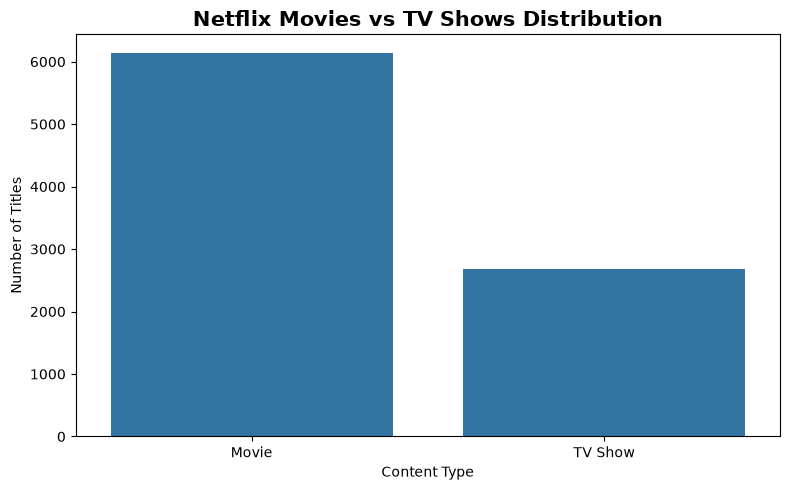

In [6]:
# Count Movies and TV Shows
content_counts = df_clean["type"].value_counts()

print("CONTENT TYPE DISTRIBUTION")
print(content_counts)

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)

plt.title("Netflix Movies vs TV Shows Distribution",
          fontsize=15, fontweight="bold")

plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

In [7]:
# Calculate content percentages
content_percentage = (
    df_clean["type"].value_counts(normalize=True) * 100
)

print("CONTENT TYPE PERCENTAGE")
print(content_percentage.round(2))

# Calculate difference
movie_count = content_counts["Movie"]
tv_count = content_counts["TV Show"]

print("\nDifference:", movie_count - tv_count)
print("Movie to TV Show Ratio:", round(movie_count / tv_count, 2))

CONTENT TYPE PERCENTAGE
type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64

Difference: 3455
Movie to TV Show Ratio: 2.29


TOP 10 COUNTRIES WITH MOST NETFLIX TITLES
country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


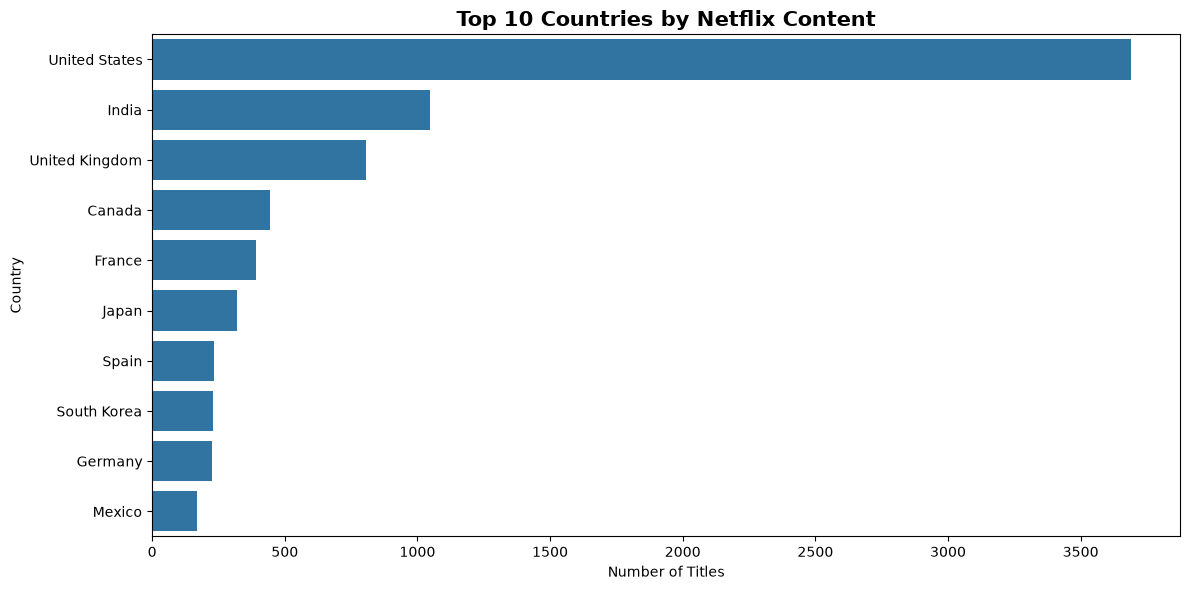

In [8]:
# Split multiple countries and count titles
country_data = df_clean["country"].str.split(",").explode()

# Remove extra spaces
country_data = country_data.str.strip()

# Exclude Unknown values
country_data = country_data[country_data != "Unknown"]

# Find top 10 countries
top_countries = country_data.value_counts().head(10)

print("TOP 10 COUNTRIES WITH MOST NETFLIX TITLES")
print(top_countries)

# Create visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Netflix Content",
          fontsize=15, fontweight="bold")

plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


CONTENT RELEASE TREND
release_year
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64


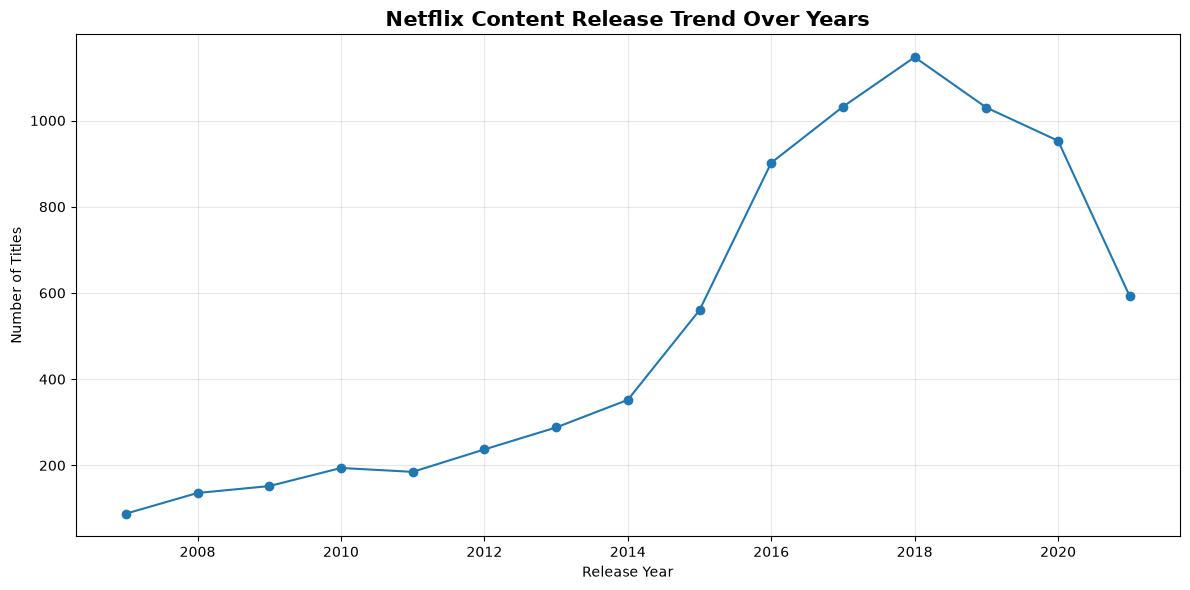

In [9]:
# Count titles released each year
year_counts = df_clean["release_year"].value_counts().sort_index()

# Display recent 15 years
recent_years = year_counts[year_counts.index >= 2007]

print("CONTENT RELEASE TREND")
print(recent_years)

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    recent_years.index,
    recent_years.values,
    marker="o"
)

plt.title("Netflix Content Release Trend Over Years",
          fontsize=15, fontweight="bold")

plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NETFLIX CONTENT RATINGS
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
Unknown        4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


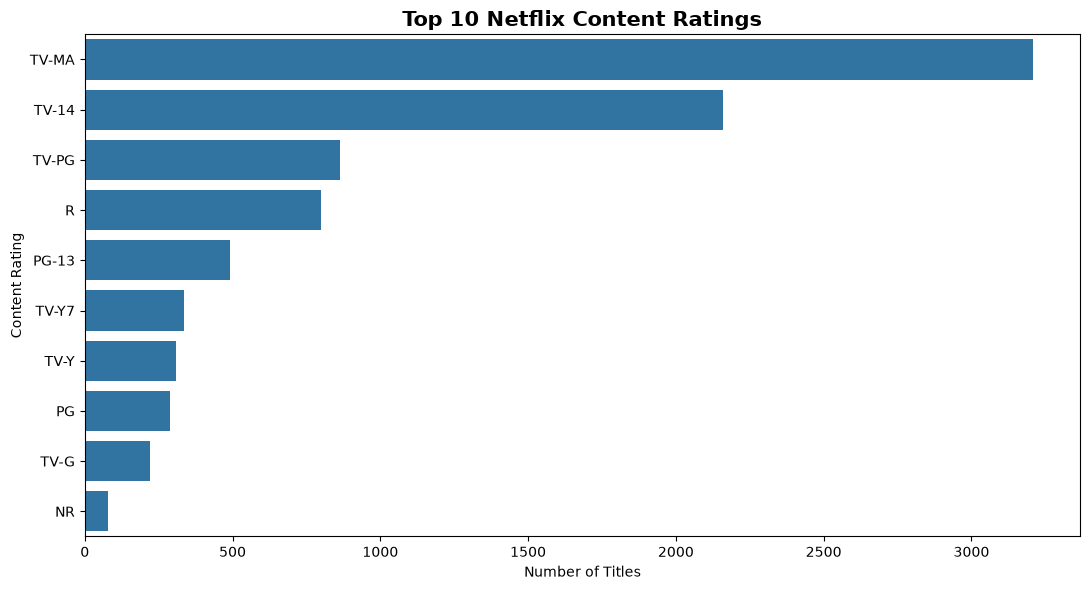

In [10]:
# Count content ratings
rating_counts = df_clean["rating"].value_counts()

print("NETFLIX CONTENT RATINGS")
print(rating_counts)

# Select top 10 ratings
top_ratings = rating_counts.head(10)

# Create visualization
plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_ratings.values,
    y=top_ratings.index
)

plt.title("Top 10 Netflix Content Ratings",
          fontsize=15, fontweight="bold")

plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")

plt.tight_layout()
plt.show()


In [11]:
# Identify unusual rating values
invalid_ratings = ["74 min", "84 min", "66 min"]

print("RECORDS WITH INCORRECT RATINGS")

display(
    df_clean[df_clean["rating"].isin(invalid_ratings)]
)

RECORDS WITH INCORRECT RATINGS


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,74 min,NaN,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,84 min,NaN,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,66 min,NaN,Movies,The comic puts his trademark hilarious/thought...


In [12]:
# Correct misplaced duration values
invalid_ratings = ["74 min", "84 min", "66 min"]

for value in invalid_ratings:
    mask = df_clean["rating"] == value

    df_clean.loc[mask, "duration"] = value
    df_clean.loc[mask, "rating"] = "Unknown"

print("INCORRECT RATINGS CORRECTED")

# Verify corrected records
display(
    df_clean[df_clean["title"].str.contains("Louis C.K.", na=False)][
        ["title", "rating", "duration"]
    ]
)

INCORRECT RATINGS CORRECTED


,title,rating,duration
5541,Louis C.K. 2017,Unknown,74 min
5794,Louis C.K.: Hilarious,Unknown,84 min
5813,Louis C.K.: Live at the Comedy Store,Unknown,66 min


In [13]:
print("DATA QUALITY VERIFICATION")

print("\nRemaining unusual ratings:")
print(
    df_clean[df_clean["rating"].str.contains("min", na=False)]["rating"]
)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDataset shape:")
print(df_clean.shape)

DATA QUALITY VERIFICATION

Remaining unusual ratings:
Series([], Name: rating, dtype: str)

Missing values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

Dataset shape:
(8807, 12)


MOVIE DURATION ANALYSIS

Average duration: 99.56 minutes
Shortest movie: 3 minutes
Longest movie: 312 minutes
Most common duration: 90 minutes


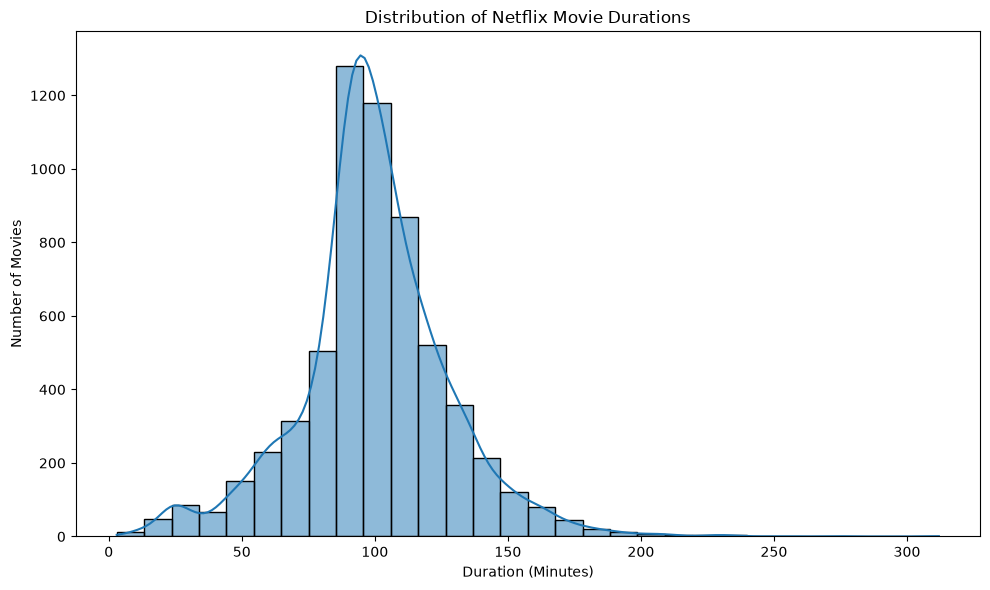

In [14]:
# Select Movies
movies = df_clean[df_clean["type"] == "Movie"].copy()

# Extract duration in minutes
movies["duration_minutes"] = (
    movies["duration"].str.replace(" min", "", regex=False)
)

movies["duration_minutes"] = pd.to_numeric(
    movies["duration_minutes"], errors="coerce"
)

# Statistical analysis
print("MOVIE DURATION ANALYSIS")

print("\nAverage duration:",
      movies["duration_minutes"].mean().round(2), "minutes")

print("Shortest movie:",
      movies["duration_minutes"].min(), "minutes")

print("Longest movie:",
      movies["duration_minutes"].max(), "minutes")

print("Most common duration:",
      movies["duration_minutes"].mode()[0], "minutes")

# Visualization
plt.figure(figsize=(10, 6))

sns.histplot(
    movies["duration_minutes"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

In [15]:
# Save cleaned dataset
df_clean.to_csv(
    "../dataset/netflix_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


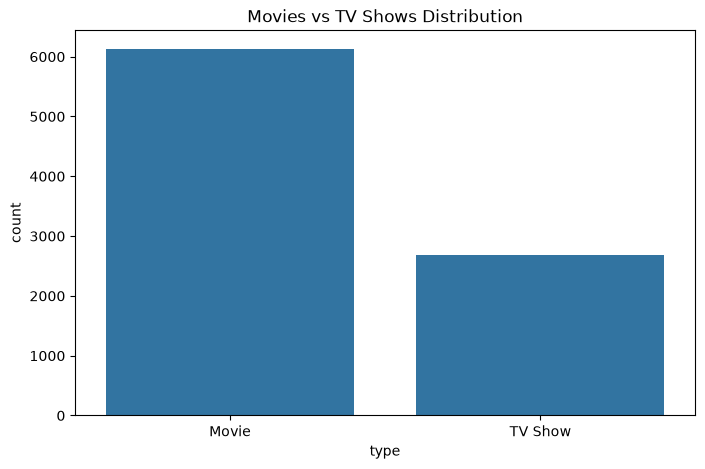

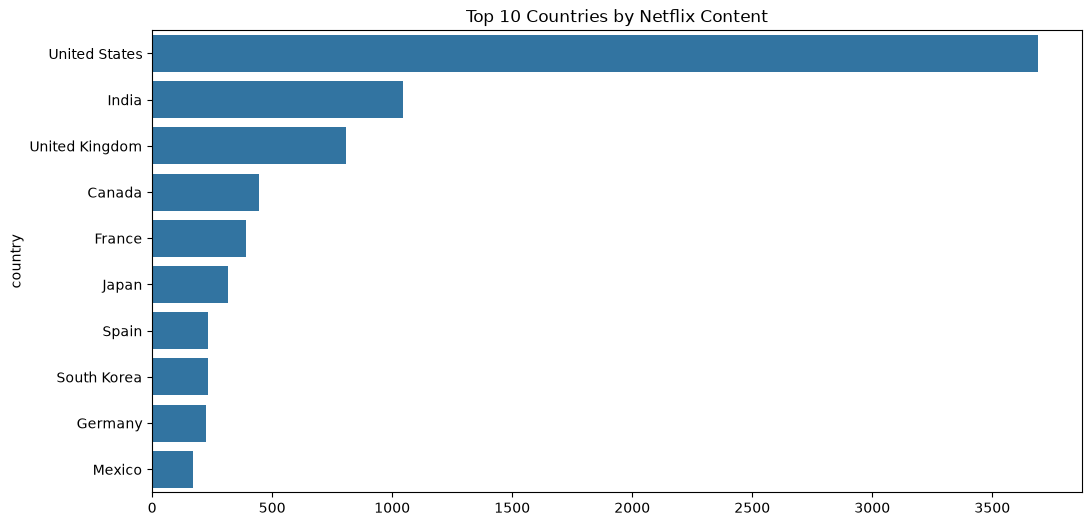

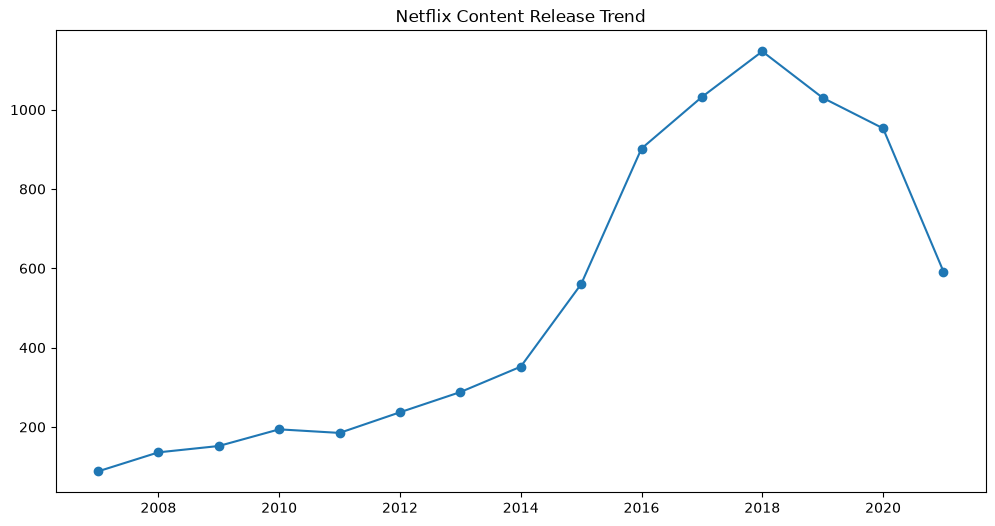

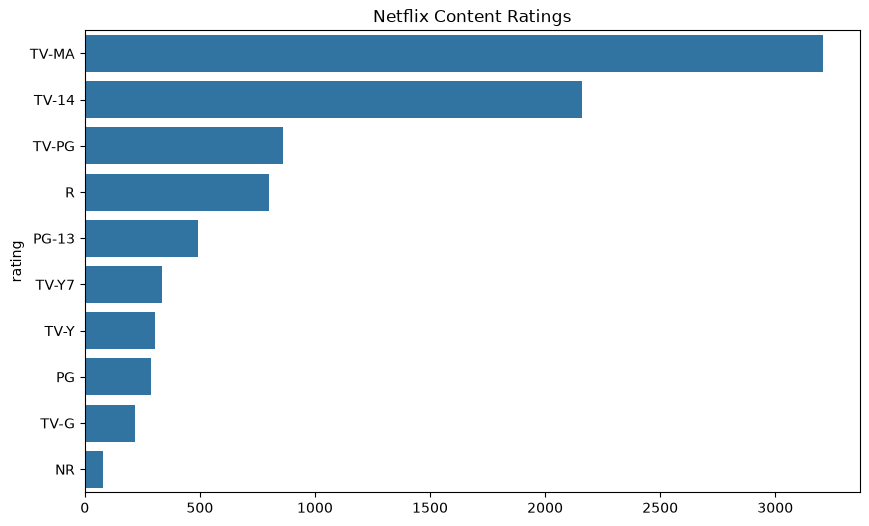

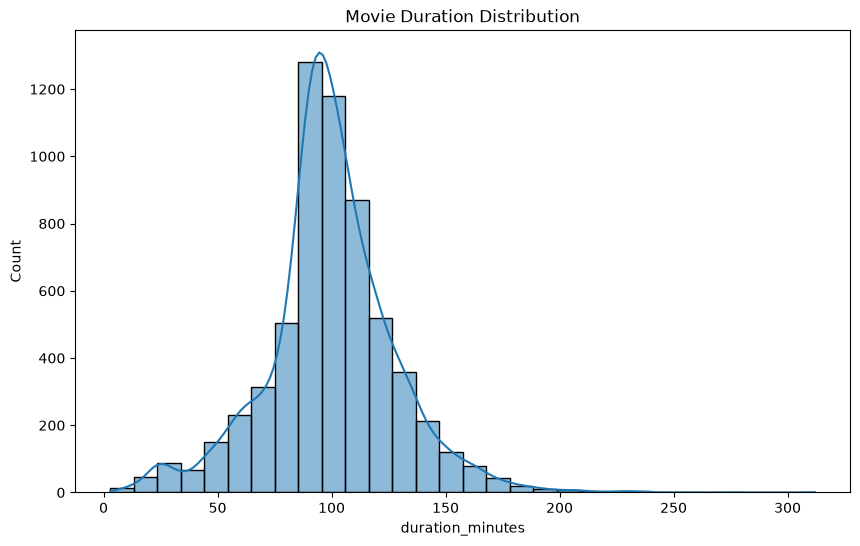

All 5 visualizations saved successfully!


In [16]:
import os

# Create visualization folder
os.makedirs("../visualizations", exist_ok=True)

# 1. Movies vs TV Shows
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="type")
plt.title("Movies vs TV Shows Distribution")
plt.savefig("../visualizations/content_distribution.png")
plt.show()

# 2. Top 10 Countries
plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries by Netflix Content")
plt.savefig("../visualizations/top_countries.png")
plt.show()

# 3. Release Year Trend
plt.figure(figsize=(12, 6))
plt.plot(recent_years.index, recent_years.values, marker="o")
plt.title("Netflix Content Release Trend")
plt.savefig("../visualizations/release_year_trend.png")
plt.show()

# 4. Content Ratings
plt.figure(figsize=(10, 6))
sns.barplot(x=top_ratings.values, y=top_ratings.index)
plt.title("Netflix Content Ratings")
plt.savefig("../visualizations/content_ratings.png")
plt.show()

# 5. Movie Duration
plt.figure(figsize=(10, 6))
sns.histplot(movies["duration_minutes"].dropna(), bins=30, kde=True)
plt.title("Movie Duration Distribution")
plt.savefig("../visualizations/movie_duration.png")
plt.show()

print("All 5 visualizations saved successfully!")

In [17]:
# ==========================================
# ADVANCED STATISTICAL ANALYSIS
# ==========================================

print("=" * 50)
print("NETFLIX DATASET - STATISTICAL ANALYSIS")
print("=" * 50)

# 1. Dataset summary
print("\n1. DATASET SUMMARY")

print("Total Titles:", len(df_clean))
print("Movies:", (df_clean["type"] == "Movie").sum())
print("TV Shows:", (df_clean["type"] == "TV Show").sum())

# 2. Content type percentages
print("\n2. CONTENT TYPE PERCENTAGES")

content_percentages = (
    df_clean["type"].value_counts(normalize=True) * 100
)

print(content_percentages.round(2))

# 3. Release year statistics
print("\n3. RELEASE YEAR STATISTICS")

print(df_clean["release_year"].describe())

# 4. Movie duration statistics
print("\n4. MOVIE DURATION STATISTICS")

print(movies["duration_minutes"].describe().round(2))

# 5. Median movie duration
median_duration = movies["duration_minutes"].median()

print("\nMedian Movie Duration:", median_duration)

# 6. Interquartile range and potential outliers
Q1 = movies["duration_minutes"].quantile(0.25)
Q3 = movies["duration_minutes"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = movies[
    (movies["duration_minutes"] < lower_limit) |
    (movies["duration_minutes"] > upper_limit)
]

print("\n5. OUTLIER ANALYSIS")

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Potential Outliers:", len(outliers))

# 7. Most common content ratings
print("\n6. TOP 5 CONTENT RATINGS")

print(df_clean["rating"].value_counts().head(5))

print("\nSTATISTICAL ANALYSIS COMPLETED!")

NETFLIX DATASET - STATISTICAL ANALYSIS

1. DATASET SUMMARY
Total Titles: 8807
Movies: 6131
TV Shows: 2676

2. CONTENT TYPE PERCENTAGES
type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64

3. RELEASE YEAR STATISTICS
count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

4. MOVIE DURATION STATISTICS
count    6131.00
mean       99.56
std        28.29
min         3.00
25%        87.00
50%        98.00
75%       114.00
max       312.00
Name: duration_minutes, dtype: float64

Median Movie Duration: 98.0

5. OUTLIER ANALYSIS
Q1: 87.0
Q3: 114.0
IQR: 27.0
Lower Limit: 46.5
Upper Limit: 154.5
Potential Outliers: 450

6. TOP 5 CONTENT RATINGS
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
Name: count, dtype: int64

STATISTICAL ANALYSIS COMPLETED!


# Netflix Movies and TV Shows — Exploratory Data Analysis (EDA)

## 1. Project Overview

This project performs Exploratory Data Analysis (EDA) on the Netflix Movies and TV Shows dataset containing 8,807 records and 12 columns.

The objective is to understand the distribution of Netflix content, identify patterns in release years, analyze country-wise content production, examine content ratings, study movie durations, and identify data quality issues.

## 2. Research Questions

1. What is the distribution of Movies and TV Shows?
2. Which countries have the highest number of Netflix titles?
3. How has the number of titles changed by release year?
4. Which content ratings are most common?
5. What is the typical duration of Netflix movies?
6. Are there missing values, duplicate records, or inconsistent data?

## 3. Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 4. Data Cleaning and Preparation

- Inspected dataset structure and column data types.
- Identified missing values.
- Replaced missing director, cast, country, and rating values with "Unknown".
- Identified and corrected three inconsistent rating entries where movie durations had been placed in the rating column.
- Retained the 10 missing date_added values for further consideration.

## 5. Exploratory Data Analysis

The analysis covers:

- Movie and TV Show distribution.
- Country-wise content distribution.
- Release-year trends.
- Content rating distribution.
- Movie duration statistics.
- Statistical summaries and potential outlier detection.

## 6. Key Findings

- The dataset contains 8,807 titles.
- Movies account for 69.62% of the dataset.
- TV Shows account for 30.38%.
- The average release year is approximately 2014.
- The median release year is 2017.
- The United States has the highest number of title-country entries, followed by India and the United Kingdom.
- 2018 has the highest number of titles in the analyzed release-year data, with 1,147 titles.
- The average movie duration is approximately 99.56 minutes.
- The most common movie duration is 90 minutes.
- Three inconsistent rating entries were identified and corrected.

## 7. Conclusion

The analysis shows that Movies make up the majority of titles in this Netflix dataset. The release-year analysis indicates a concentration of titles from more recent years, particularly between 2015 and 2020.

The country-wise analysis highlights the United States and India among the leading countries by title-country entries. Movie duration analysis shows an average duration of approximately 100 minutes.

Data cleaning improved the consistency of the dataset, while visualizations and statistical summaries helped identify important patterns.

This project demonstrates the use of Python-based data analysis techniques to explore a real-world dataset, identify data quality issues, summarize trends, and communicate findings through visualizations.

## 8. Project Deliverables

- Cleaned Netflix dataset.
- Exploratory Data Analysis notebook.
- Five exported visualizations.
- Statistical analysis and findings.
- Final EDA report.